In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import subprocess
import sys
from pathlib import Path

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_data(file_path):
    """
    Loads a two-column Parquet file and converts it back into a Python dictionary.
    """
    # 1. Read the Parquet file into a DataFrame
    df = pd.read_parquet(file_path)
    
    # 2. Zip the 'key' and 'value' columns together and convert to a dict
    return dict(zip(df['key'], df['value']))

In [3]:
# --- Load data files ---
ROOT_PATH = "/data/pgangwar/vaccinescout/data/"
DATA_PATH = ROOT_PATH + "final_df.parquet"

current_dict = ROOT_PATH + "current_id_to_seq.parquet"
dist_parquet = ROOT_PATH + "pairwise_dist.parquet"
curr_seq_mut_sites_parquet = ROOT_PATH + "current_sequence_mutation_sites.parquet"
curr_seq_escape_score_parquet = ROOT_PATH + "current_sequence_escape_scores.parquet"

final_df = pd.read_parquet(DATA_PATH)

id_to_seq = load_data(ROOT_PATH + "sequence_dict.parquet")

refSeq = getReference(ROOT_PATH + 'ref_spike_genome.fa')

vaccine_df = pd.read_pickle(ROOT_PATH + 'vaccine_recommendations.pkl')

ver = 'Jan_4_24'

pyro_df = pd.read_pickle(ROOT_PATH + f'pyro_ver/{ver}/PyroSpike.pkl')

escape_calc_strain = 'SARS'

In [5]:
# --- Define cutoff date ---
cutoff_date = "2022-07-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
#disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']
disjoint_windows = ['6M_1', '6M_2']

# --- Perform slicing ---
future_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Summary output ---
# print(f"Cumulative slices: {list(cumulative_slices.keys())}")
print(f"Disjoint slices: {list(disjoint_slices.keys())}")
print(f"Total future slices stored: {len(future_slices)}")

Disjoint slices: ['3M_1', '3M_2', '3M_3', '3M_4']
Total future slices stored: 4


In [6]:
# --- Group by sequence ID and count tips ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

min_tip_count = 5
current_seq_df = (
    current_seq_df[current_seq_df['Tip_Count'] >= min_tip_count]
    .reset_index(drop=True)
)

future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}

print("Total Tips:", len(current_df))
print("Total Spikes:", len(current_seq_df))

Total Tips: 539081
Total Spikes: 3023


In [7]:
# Prepare mutation sites for escape calculation

def save_curr_seq_sites_to_file(sequence_dict, ref_seq, output_filename):
    """
    Write ``sequence_dict`` ({ID: spike AA sequence}) to a two-column Parquet file
    with the same ``key`` / ``value`` layout as ``load_data`` expects.

    Each ``value`` is a list of 1-indexed spike residue sites that differ from
    ``ref_seq``, using ``compute_mutations`` and ``get_mutation_pattern`` (sites only,
    not full mutation strings).

    """
    keys = []
    site_lists = []
    for seq_id, sequence in sequence_dict.items():
        sites = []
        for mut in compute_mutations(sequence, ref_seq):
            _, site, _ = get_mutation_pattern(mut)
            if site:
                sites.append(int(site))
        keys.append(seq_id)
        site_lists.append(sites)

    pd.DataFrame({"key": keys, "value": site_lists}).to_parquet(
        output_filename, index=False
    )


# Mutated spike sites only (Parquet); full sequences remain in ``id_to_seq`` / pairwise step
current_sequences_dict = {
    seq_id: id_to_seq[seq_id]
    for seq_id in current_seq_df["Sequence_ID"]
    if seq_id in id_to_seq
}
save_curr_seq_sites_to_file(
    current_sequences_dict,
    refSeq,
    curr_seq_mut_sites_parquet,
)

In [8]:
# Calculate escape scores

def run_calculate_escape(variant, input_parquet, output_parquet):
    """Run ``scripts/calculate_escape.py`` on mutated-site Parquet; writes escape scores."""
    script_path = None
    _p = Path.cwd().resolve()
    for _ in range(12):
        _c = _p / "scripts" / "calculate_escape.py"
        if _c.is_file():
            script_path = _c
            break
        if _p.parent == _p:
            break
        _p = _p.parent
    if script_path is None:
        script_path = Path.cwd() / "scripts" / "calculate_escape.py"
    if not script_path.is_file():
        raise FileNotFoundError(
            f"calculate_escape.py not found at {script_path.resolve()}"
        )
    cmd = [
        sys.executable,
        str(script_path.resolve()),
        "--variant",
        str(variant),
        "-i",
        str(input_parquet),
        "-o",
        str(output_parquet),
    ]
    print("Running:", " ".join(cmd))
    subprocess.run(cmd, check=True)


run_calculate_escape(
    escape_calc_strain,
    curr_seq_mut_sites_parquet,
    curr_seq_escape_score_parquet,
)

Running: /home/pgangwar@AD.UCSD.EDU/miniconda3/envs/ipynb-env/bin/python /home/pgangwar@AD.UCSD.EDU/FutureCoV/scripts/calculate_escape.py --variant SARS -i /data/pgangwar/vaccinescout/data/current_sequence_mutation_sites.parquet -o /data/pgangwar/vaccinescout/data/current_sequence_escape_scores.parquet


In [13]:
# -- Process Sequence Weights --- 
current_seq_df["Weight"] = current_seq_df["Tip_Count"] / current_seq_df["Tip_Count"].sum()

for interval, df in future_seq_dfs.items():
    # Calculate the normalized weight (sums to 1)
    df["Weight"] = df["Tip_Count"] / df["Tip_Count"].sum()

In [14]:
# --- Compute nearest-neighbour distances within the current cohort via scripts/pairwise_dist ---
import subprocess
import pyarrow as pa
import pyarrow.parquet as pq
from pathlib import Path

cohort_dir = Path(ROOT_PATH.rstrip("/")) / cutoff_date
cohort_dir.mkdir(parents=True, exist_ok=True)

current_seq_ids = current_seq_df["Sequence_ID"].tolist()
pq.write_table(
    pa.table({
        "key":   pa.array(current_seq_ids, type=pa.string()),
        "value": pa.array([id_to_seq[sid] for sid in current_seq_ids], type=pa.string()),
    }),
    str(current_dict),
)

pairwise_dist_bin = None
_p = Path.cwd().resolve()
for _ in range(12):
    _c = _p / "scripts" / "pairwise_dist"
    if _c.is_file():
        pairwise_dist_bin = _c
        break
    if _p.parent == _p:
        break
    _p = _p.parent
if pairwise_dist_bin is None:
    pairwise_dist_bin = Path.cwd() / "scripts" / "pairwise_dist"
if not pairwise_dist_bin.is_file():
    raise FileNotFoundError(
        f"pairwise_dist not found at {pairwise_dist_bin.resolve()}. From repo root: "
        "cmake -S scripts -B scripts/build && cmake --build scripts/build -j"
    )

cmd = [
    str(pairwise_dist_bin.resolve()),
    "--parquet", str(current_dict),
    "--output", str(dist_parquet),
]
print("Running:", " ".join(cmd))
subprocess.run(cmd, check=True)

dist_df = pd.read_parquet(dist_parquet, engine="pyarrow")

Running: /home/pgangwar@AD.UCSD.EDU/FutureCoV/scripts/pairwise_dist --parquet /data/pgangwar/vaccinescout/data/current_id_to_seq.parquet --output /data/pgangwar/vaccinescout/data/pairwise_dist.parquet


pairwise_dist (compute) 3023 / 3023
pairwise_dist (write)   3023 / 3023 (9138529 rows)


wrote "/data/pgangwar/vaccinescout/data/pairwise_dist.parquet" (9138529 rows)


Preprocess Weights and Distance

In [15]:
def preprocess_for_weighted_pam_fast(current_seq_df: pd.DataFrame, dist_df: pd.DataFrame):
    """
    Fast vectorized preprocessing for weighted PAM.

    Args:
        current_seq_df: pd.DataFrame with columns ['Sequence_ID', 'Weight']
        dist_df: pd.DataFrame with columns ['Seq_1', 'Seq_2', 'Distance']

    Returns:
        dist_matrix: np.ndarray of shape (N, N), symmetric distance matrix
        weights: np.ndarray of shape (N,), aligned to matrix
        id2idx: dict mapping Sequence_ID -> index
        idx2id: dict mapping index -> Sequence_ID
    """
    # Index sequences
    sequence_ids = current_seq_df['Sequence_ID'].tolist()
    id2idx = {sid: i for i, sid in enumerate(sequence_ids)}
    idx2id = {i: sid for sid, i in id2idx.items()}
    n = len(sequence_ids)

    # Vectorized index lookup
    i_indices = dist_df['Seq_1'].map(id2idx).to_numpy()
    j_indices = dist_df['Seq_2'].map(id2idx).to_numpy()
    distances = dist_df['Distance'].to_numpy(dtype=np.float32)

    # Fill symmetric distance matrix
    dist_matrix = np.zeros((n, n), dtype=np.float32)
    dist_matrix[i_indices, j_indices] = distances

    # Prepare weights vector
    weights_series = current_seq_df.set_index('Sequence_ID')['Weight']
    weights = np.array([weights_series[idx2id[i]] for i in range(n)], dtype=np.float32)

    # Create a fast dictionary lookup: {Sequence_ID: Score}
    if os.path.exists(curr_seq_escape_score_parquet):
        scores_df = pd.read_parquet(curr_seq_escape_score_parquet)
        score_dict = scores_df.set_index('name')['neutralization_retained'].to_dict()
    
        # Build the aligned array using your existing idx2id mapping and n
        # If a sequence is missing from the scores file, it defaults to 1.0
        nr_scores = np.array([score_dict.get(idx2id[i], 1.0) for i in range(n)], dtype=np.float32)
        print(f"Loaded NR scores for {len(score_dict)} sequences.")
    else:
        nr_scores = None
        print(f"File {curr_seq_escape_score_parquet} not found. Running standard unpenalized PAM.")

    return dist_matrix, weights, id2idx, idx2id, nr_scores

In [16]:
dist_matrix, weights, id2idx, idx2id, nr_scores = preprocess_for_weighted_pam_fast(current_seq_df, dist_df)

Loaded NR scores for 3023 sequences.


PAM Code - Driving Function of Medoid Selection

In [18]:
# A "weight_fn" transforms the per-sequence `weights` vector.
# A "modifier_fn" transforms the per-sequence `nr_scores` into a multiplicative
# distance modifier applied to each candidate column.
#
# Cost minimized by weighted_pam:
#     sum_i  weight_fn(weights)[i]  *  min_m  ( dist_matrix[i, m] * modifier_fn(nr_scores)[m] )

# Role of `alpha` per function:
#   power : x ** alpha
#   exp   : alpha ** x
#   log   : np.log(x) / np.log(alpha)   -> base alpha;  np.log (natural, base e) if alpha is None
# linear / sqrt / square / ones ignore alpha.

def _log(x, alpha):
    return np.log(x) if alpha is None else np.log(x) / np.log(alpha)

WEIGHT_FNS = {
    "linear": lambda w, alpha=None: w,
    "log":    lambda w, alpha=None: _log(w, alpha),
    "sqrt":   lambda w, alpha=None: np.sqrt(w),
    "square": lambda w, alpha=None: w ** 2,
}

MODIFIER_FNS = {
    "ones":   lambda s, alpha=None: np.ones_like(s),
    "linear": lambda s, alpha=None: 1 + s,
    "power":  lambda s, alpha=1.0:  (1 + s) ** alpha,
    "exp":    lambda s, alpha=np.e: np.power(alpha, s),
    "log":    lambda s, alpha=None: _log(s + 1, alpha),
}


def weighted_pam(
    dist_matrix,
    weights,
    k,
    nr_scores=None,
    weight_fn="linear",
    modifier_fn=None,
    alpha=None,
    max_iter=100,
    verbose=False,
):
    """
    Weighted PAM clustering with greedy BUILD + SWAP.

    Effective cost:
        sum_i  w_eff[i] * min_m ( dist_matrix[i, m] * modifiers[m] )

    where
        w_eff[i]     = WEIGHT_FNS[weight_fn](weights[i],   alpha)
        modifiers[i] = MODIFIER_FNS[modifier_fn](nr_scores[i], alpha)
                       (ones if nr_scores is None or modifier_fn is None)

    `alpha` is shared by weight_fn and modifier_fn:
        power -> x ** alpha
        exp   -> alpha ** x
        log   -> log base `alpha`     (natural log, base e, if alpha is None)
        log1p -> log1p base `alpha`   (natural, base e, if alpha is None)

    Examples:
        weighted_pam(..., weight_fn="linear", modifier_fn="power", alpha=10.0)
        weighted_pam(..., weight_fn="log",    modifier_fn="linear", alpha=10) # log10(weights) * scores
        weighted_pam(..., weight_fn="log",    modifier_fn="linear")           # ln(weights) * scores

    Returns:
        medoids: list of medoid indices
        labels: np.ndarray, assigned medoid index for each point
        final_cost: float, weighted clustering cost
    """
    n = dist_matrix.shape[1]
    if k <= 0 or k > n:
        raise ValueError("k must be between 1 and N")

    w_fn = WEIGHT_FNS[weight_fn]
    w_eff = np.asarray(w_fn(weights, alpha=alpha), dtype=np.float32)

    if nr_scores is None or modifier_fn is None:
        modifiers = np.ones(n, dtype=np.float32)
    else:
        m_fn = MODIFIER_FNS[modifier_fn]
        s_arr = np.asarray(nr_scores, dtype=np.float32)
        modifiers = np.asarray(m_fn(s_arr, alpha=alpha), dtype=np.float32)

    # --- BUILD Phase ---
    remaining = set(range(n))
    medoids = []

    # First medoid: minimize sum_i f_i * d(i, candidate) -> Based on idea that low value of nr_scores makes a variant more dangerous
    total_weighted_dists = (dist_matrix * w_eff.reshape(1, -1)).sum(axis=1) * modifiers
    first = int(np.argmin(total_weighted_dists))
    medoids.append(first)
    remaining.remove(first)

    def assign_to_medoids(dist_matrix, medoids):
        d_to_m = dist_matrix[:, medoids] * modifiers[medoids]
        nearest_idx = np.argmin(d_to_m, axis=1)
        # Distance to the closest medoid
        dist1 = d_to_m[np.arange(n), nearest_idx]
        d_to_m_tmp = d_to_m.copy()
        d_to_m_tmp[np.arange(n), nearest_idx] = np.inf
        # Distance to the second closest medoid
        dist2 = d_to_m_tmp[np.arange(n), np.argmin(d_to_m_tmp, axis=1)]
        # Nearest medoid to each sequence
        nearest_medoid = np.array(medoids)[nearest_idx]
        return nearest_idx, nearest_medoid, dist1, dist2

    _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    for _ in range(1, k):
        best_candidate = None
        best_cost = np.inf
        for c in remaining:
            new_dist = np.minimum(dist1, dist_matrix[:, c] * modifiers[c])
            cost_if_added = float(np.dot(w_eff, new_dist))
            if cost_if_added < best_cost:
                best_cost = cost_if_added
                best_candidate = c
        medoids.append(int(best_candidate))
        remaining.remove(best_candidate)
        _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    if verbose:
        print(f"[BUILD] Initial medoids: {medoids}")

    # --- SWAP phase ---
    it = 0
    improved = True
    history = []

    while improved and it < max_iter:
        improved = False
        best_delta = 0
        best_swap = None
        medoids_set = set(medoids)

        nearest_idx, nearest_medoid, dist1, dist2 = assign_to_medoids(dist_matrix, medoids)

        for m_pos, m in enumerate(medoids):
            for h in range(n):
                if h in medoids_set:
                    continue
                d_ih = dist_matrix[:, h] * modifiers[h]
                mask_better = d_ih < dist1
                delta_better = ((d_ih - dist1) * w_eff)[mask_better].sum()
                mask_owned_by_m = (nearest_medoid == m)
                mask_case2 = mask_owned_by_m & (~mask_better)
                new_dist_case2 = np.minimum(dist2, d_ih)
                delta_case2 = ((new_dist_case2 - dist1) * w_eff)[mask_case2].sum()
                delta = delta_better + delta_case2
                if delta < best_delta:
                    best_delta = delta
                    best_swap = (m_pos, h)

        if best_swap and best_delta < -1e-12:
            m_pos, h = best_swap
            medoids[m_pos] = h
            improved = True
        else:
            break
        it += 1

    # final assignment
    _, nearest_medoid, dist1, _ = assign_to_medoids(dist_matrix, medoids)
    final_cost = float(np.dot(w_eff, dist1))
    labels = nearest_medoid.copy()

    return medoids, labels, final_cost

In [51]:
# --- Pick a (weight_fn, modifier_fn) combo to experiment with ---
# Names refer to keys in WEIGHT_FNS / MODIFIER_FNS. Callables are also accepted.
# A single `ALPHA` is shared between both transforms:
#   power -> x ** ALPHA      exp -> ALPHA ** x
#   log   -> log_ALPHA(x)
#   linear / sqrt / square / ones ignore ALPHA.
#
# Examples to try:
#   ("linear", "power", 10.0)  -> dist * weights * nr_scores ** 10
#   ("log",    "linear", None) -> dist * ln(weights) * nr_scores
#   ("sqrt",   "power", 2.0)   -> dist * sqrt(weights) * nr_scores ** 2
#   ("linear", "exp",   10.0)  -> dist * weights * 10 ** nr_scores
#   ("log",    "exp",   10.0)  -> dist * log10(weights) * 10 ** nr_scores

WEIGHT_FN = "linear"
MODIFIER_FN = "exp"
ALPHA = 2.0

print(f"Config -> weight_fn={WEIGHT_FN!r}, modifier_fn={MODIFIER_FN!r}, alpha={ALPHA}")

pam_results = {}

for k in range(1, 5):  # K = 1 to 4
    print(f"\nRunning weighted PAM for K = {k}")

    medoids, labels, cost = weighted_pam(
        dist_matrix,
        weights,
        k=k,
        nr_scores=nr_scores,
        weight_fn=WEIGHT_FN,
        modifier_fn=MODIFIER_FN,
        alpha=ALPHA,
        max_iter=100,
        verbose=False,
    )

    # Map indices back to sequence IDs
    medoid_ids = [idx2id[i] for i in medoids]
    label_ids = [idx2id[i] for i in labels]

    # Store results in dict
    pam_results[k] = {
        'medoids': medoid_ids,
        'labels': label_ids,
        'cost': cost,
    }

Config -> weight_fn='linear', modifier_fn='exp', alpha=2.0

Running weighted PAM for K = 1

Running weighted PAM for K = 2

Running weighted PAM for K = 3

Running weighted PAM for K = 4


In [52]:
####DEBUG

# --- Assign each medoid to lineage group(s) from lineage_spike.fasta ---
from Bio import SeqIO
from datetime import datetime

LINEAGE_SPIKE_FASTA = Path(ROOT_PATH) / "lineage_spike.fasta"
MEDOID_LINEAGE_LOG = Path(ROOT_PATH) / f"medoid_lineage_assignments_{WEIGHT_FN}_{MODIFIER_FN}_{ALPHA}.log"


def spike_mutation_distance(seq_a: str, seq_b: str) -> int:
    """Number of differing amino-acid sites (Hamming distance)."""
    if len(seq_a) != len(seq_b):
        raise ValueError(
            f"Sequence length mismatch: {len(seq_a)} vs {len(seq_b)}"
        )
    return sum(a != b for a, b in zip(seq_a, seq_b))


def load_lineage_spike_groups(fasta_path: Path):
    groups = []
    for record in SeqIO.parse(str(fasta_path), "fasta"):
        lineages = record.id.split("|")
        groups.append(
            {
                "header": record.id,
                "lineages": lineages,
                "sequence": str(record.seq),
            }
        )
    return groups


def assign_medoid_lineages(medoid_seq: str, lineage_groups):
    """Return exact lineage header or closest matching group(s) with distance."""
    exact = [g for g in lineage_groups if medoid_seq == g["sequence"]]
    if exact:
        return {
            "match_type": "exact",
            "lineage_groups": [g["header"] for g in exact],
            "distance": 0,
            "closest": [(g["header"], 0) for g in exact],
        }

    distances = [
        (g["header"], spike_mutation_distance(medoid_seq, g["sequence"]))
        for g in lineage_groups
    ]
    min_dist = min(d for _, d in distances)
    closest = [(header, dist) for header, dist in distances if dist == min_dist]
    closest.sort(key=lambda x: x[0])

    return {
        "match_type": "closest",
        "lineage_groups": [header for header, _ in closest],
        "distance": min_dist,
        "closest": closest,
    }


def format_medoid_assignment_log(k, sid, assignment, missing=False):
    lines = [f"K={k}\tSequence_ID={sid}"]
    if missing:
        lines.append("  status: missing from id_to_seq")
        return lines

    lines.append(f"  match_type: {assignment['match_type']}")
    lines.append(f"  mutation_distance: {assignment['distance']}")

    if assignment["match_type"] == "exact":
        lines.append(f"  lineage_group: {assignment['lineage_groups'][0]}")
    else:
        lines.append("  closest_lineage_groups:")
        for header, dist in assignment["closest"]:
            lines.append(f"    - {header} ({dist})")

    return lines


lineage_groups = load_lineage_spike_groups(LINEAGE_SPIKE_FASTA)
medoid_lineage_assignments = {}
medoid_lineage_rows = []
log_lines = [
    "Medoid lineage assignment log",
    f"Generated: {datetime.now().isoformat(timespec='seconds')}",
    f"Lineage reference: {LINEAGE_SPIKE_FASTA}",
    f"N lineage spike groups: {len(lineage_groups)}",
    "",
]

for k, res in sorted(pam_results.items()):
    medoid_ids = res["medoids"]
    k_assignments = {}
    log_lines.append(f"=== K = {k} ===")

    for sid in medoid_ids:
        seq = id_to_seq.get(sid)
        if seq is None:
            log_lines.extend(format_medoid_assignment_log(k, sid, None, missing=True))
            medoid_lineage_rows.append(
                {
                    "K": k,
                    "Sequence_ID": sid,
                    "match_type": "missing",
                    "mutation_distance": None,
                    "lineage_group": None,
                    "closest_lineage_groups": None,
                }
            )
            continue

        assignment = assign_medoid_lineages(seq, lineage_groups)
        k_assignments[sid] = assignment
        log_lines.extend(format_medoid_assignment_log(k, sid, assignment))
        medoid_lineage_rows.append(
            {
                "K": k,
                "Sequence_ID": sid,
                "match_type": assignment["match_type"],
                "mutation_distance": assignment["distance"],
                "lineage_group": assignment["lineage_groups"][0],
                "closest_lineage_groups": "; ".join(
                    f"{header} ({dist})" for header, dist in assignment["closest"]
                ),
            }
        )

    medoid_lineage_assignments[k] = k_assignments
    log_lines.append("")

MEDOID_LINEAGE_LOG.write_text("\n".join(log_lines), encoding="utf-8")
medoid_lineage_df = pd.DataFrame(medoid_lineage_rows)

print(f"Loaded {len(lineage_groups)} lineage spike group(s) from {LINEAGE_SPIKE_FASTA}")
print(f"Wrote medoid lineage log for {len(medoid_lineage_rows)} medoid(s) to {MEDOID_LINEAGE_LOG}")

Loaded 2197 lineage spike group(s) from /data/pgangwar/vaccinescout/data/lineage_spike.fasta
Wrote medoid lineage log for 10 medoid(s) to /data/pgangwar/vaccinescout/data/medoid_lineage_assignments_linear_exp_2.0.log


FDA Recommended Strains

In [29]:
# --- Load clade sequences for FDA recommended Strains ---
vaccine_df = vaccine_df.rename(columns={'clade': 'Sequence_ID'})
clade_to_seq = dict(zip(vaccine_df['Sequence_ID'], vaccine_df['mutated_sequence']))

Evaluation and Comparisons

In [22]:
from tqdm import tqdm

def np_hamming_distance_matrix(sequences1, sequences2):
    """
    Computes the Hamming distance matrix between two lists/arrays of sequences.
    Assumes sequences are of the same length and contain standard characters (e.g., A, C, G, T).

    Args:
        sequences1 (list of str): The first set of sequences (rows).
        sequences2 (list of str): The second set of sequences (columns/medoids).

    Returns:
        np.ndarray: A matrix where matrix[i, j] is the Hamming distance
                    between sequences1[i] and sequences2[j].
    """
    if not sequences1 or not sequences2:
        return np.array([[]])

    # Convert lists of strings to NumPy character arrays.
    arr1 = np.array([list(s) for s in sequences1])
    arr2 = np.array([list(s) for s in sequences2])
    
    # Summing along the character axis (axis 2) gives the distance
    return np.sum(np.not_equal(arr1[:, None, :], arr2[None, :, :]), axis=2)


def evaluate_medoids_vectorized(medoids, id_to_seq_, future_seq_dfs):
    """
    Compute weighted average distance of future sequences to nearest medoid using
    vectorized operations (optimized for Hamming distance).

    Args:
        medoids: list of Sequence_IDs selected as medoids.
        id_to_seq_: dict mapping Sequence_ID -> sequence string.
        future_seq_dfs: dict of interval -> DataFrame(Sequence_ID, Tip_Count/Weight).

    Returns:
        results: dict of interval -> weighted average min distance.
    """
    # Precompute medoid sequences
    medoid_seqs = [id_to_seq_[mid] for mid in medoids]

    results = {}

    for interval, df in future_seq_dfs.items():
        # Module 1: Data Preparation
        # Retrieve all sequences and corresponding weights (Tip_Count)
        if df.empty:
            results[interval] = 0.0
            continue

        future_seq_ids = df['Sequence_ID'].tolist()
        future_seqs = [id_to_seq_[sid] for sid in future_seq_ids]
        weights = df['Weight'].values

        if not future_seqs:
             results[interval] = 0.0
             continue

        with tqdm(total=1, desc=f"Calculating Distances for {interval}") as p:
            distance_matrix = np_hamming_distance_matrix(future_seqs, medoid_seqs)
            p.update(1)

        # Find the minimum distance to any medoid for each sequence (min over columns)
        min_distances = np.min(distance_matrix, axis=1)

        # Module 3: Weighted Average Calculation
        # Vectorized weighted average computation.
        total_weight = np.sum(weights)
        if total_weight == 0:
            weighted_avg = 0.0
        else:
            weighted_avg = np.sum(min_distances * weights) / total_weight

        results[interval] = weighted_avg

    return results

In [41]:
# --- Evaluate medoids for K = 1 to 4 on Future Data ---
medoid_evaluation_results = {}

for k in range(1, 5):  
    print(f"\nEvaluating medoids for K = {k}")
    medoid_ids = pam_results[k]['medoids']

    weighted_avg_dists = evaluate_medoids_vectorized(
        medoids=medoid_ids,
        id_to_seq_=id_to_seq,
        future_seq_dfs=future_seq_dfs
    )

    medoid_evaluation_results[k] = weighted_avg_dists


Evaluating medoids for K = 1


Calculating Distances for 3M_4: 100%|█████████████████████████| 1/1 [00:04<00:00,  4.44s/it]



Evaluating medoids for K = 2


Calculating Distances for 3M_4: 100%|█████████████████████████| 1/1 [00:04<00:00,  4.31s/it]



Evaluating medoids for K = 3


Calculating Distances for 3M_4: 100%|█████████████████████████| 1/1 [00:04<00:00,  4.45s/it]



Evaluating medoids for K = 4


Calculating Distances for 3M_4: 100%|█████████████████████████| 1/1 [00:04<00:00,  4.72s/it]


In [30]:
from tqdm import tqdm

def evaluate_vaccines_vectorized(vaccines, vaccine_to_seq, id_to_seq, future_seq_dfs):
    """
    Compute weighted average distance of future sequences to nearest vaccine medoid.
    
    Args:
        vaccines: list of vaccine IDs.
        vaccine_to_seq: dict mapping vaccine ID -> sequence string.
        id_to_seq: dict mapping future Sequence_ID -> sequence string.
        future_seq_dfs: dict of interval -> DataFrame(Sequence_ID, Weight).

    Returns:
        results: dict of interval -> weighted average min distance.
    """
    # Retrieve sequences for the vaccine list using its specific dictionary
    # Validation: Ensure all vaccines exist in vaccine_to_seq
    medoid_seqs = [vaccine_to_seq[vid] for vid in vaccines if vid in vaccine_to_seq]
    
    if not medoid_seqs:
        return {interval: 0.0 for interval in future_seq_dfs}

    results = {}

    for interval, df in future_seq_dfs.items():
        if df.empty:
            results[interval] = 0.0
            continue

        # Filter future IDs to ensure they exist in id_to_seq to prevent KeyErrors
        valid_df = df[df['Sequence_ID'].isin(id_to_seq)]
        
        if valid_df.empty:
            results[interval] = 0.0
            continue

        future_seq_ids = valid_df['Sequence_ID'].tolist()
        future_seqs = [id_to_seq[sid] for sid in future_seq_ids]
        weights = valid_df['Weight'].values

        # Optimized Hamming Calculation
        with tqdm(total=1, desc=f"Calculating Distances for {interval}") as p:
            # np_hamming_distance_matrix remains the same as previously defined
            distance_matrix = np_hamming_distance_matrix(future_seqs, medoid_seqs)
            p.update(1)

        # Minimum distance to any of the provided vaccines
        min_distances = np.min(distance_matrix, axis=1)

        # Weighted Average
        total_weight = np.sum(weights)
        if total_weight == 0:
            weighted_avg = 0.0
        else:
            weighted_avg = np.sum(min_distances * weights) / total_weight

        results[interval] = weighted_avg

    return results

In [31]:
# --- Evaluate FDA recommended strains --- 
recommended_strains = ['BA.4', 'BA.5']
vaccine_evaluation_results = {
    strain: evaluate_vaccines_vectorized(
        vaccines=[strain], 
        vaccine_to_seq=clade_to_seq, 
        id_to_seq=id_to_seq, 
        future_seq_dfs=future_seq_dfs
    )
    for strain in recommended_strains
}

Calculating Distances for 3M_4: 100%|█████████████████████████| 1/1 [00:04<00:00,  4.18s/it]


Plotting Performance

In [24]:
def plot_medoid_performance(pam_results, medoid_evaluation_results, cutoff_date):
    """
    Plots medoid coverage cost and future interval distances.
    
    Args:
        pam_results: dict[k]['cost'] -> numeric cost for current/training data
        medoid_evaluation_results: dict[k][interval] -> numeric avg distance
        cutoff_date: str for plot title metadata
    """
    # Publication Style Settings (Nature-level)
    plt.rcParams.update({
        'font.size': 12,
        'axes.labelsize': 14,
        'axes.titlesize': 14,
        'xtick.labelsize': 13,
        'ytick.labelsize': 13,
        'legend.fontsize': 10
    })

    plt.figure(figsize=(8, 6))
    
    # Extract K values (X-axis) and sort them
    k_values = sorted(medoid_evaluation_results.keys())
    
    # Mapping for interval labels
    slice_labels = {
        "3M_1": "0-3 Months",
        "3M_2": "3-6 Months",
        "3M_3": "6-9 Months",
        "3M_4": "9-12 Months"
    }
    
    # 1. Plot the Current/Training Cost (Black line)
    current_y = [pam_results[k]['cost'] for k in k_values]
    plt.plot(k_values, current_y, marker='o', color='black', linestyle='--', 
             label='Current Sequences (Weighted)', zorder=5, alpha=0.75)
    
    # Add annotations for the black line
    for xi, yi in zip(k_values, current_y):
        plt.text(xi, yi - 0.4, f"{yi:.3f}", color='black', ha='center', va='top', fontsize=8)

    # 2. Plot the Future Intervals
    # Get all slice keys from the first available K
    interval_keys = list(next(iter(medoid_evaluation_results.values())).keys())
    colors = sns.color_palette("colorblind", n_colors=len(interval_keys))

    for idx, interval_key in enumerate(interval_keys):
        y_vals = [medoid_evaluation_results[k][interval_key] for k in k_values]
        label = slice_labels.get(interval_key, interval_key)
        
        plt.plot(k_values, y_vals, marker='x', color=colors[idx], 
                 label=label, alpha=1)
        
        # Add annotations for intervals (reduced size for clarity)
        for xi, yi in zip(k_values, y_vals):
            plt.text(xi, yi + 0.25, f"{yi:.3f}", color=colors[idx], ha='center', va='bottom', fontsize=10, fontweight='bold')

    # Formatting
    plt.xlabel("Number of Medoids ($K$)")
    plt.ylabel("Average Minimum Mutation Distance")
    
    plt.xticks(k_values)
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5, frameon=True, borderaxespad=0.)
    
    # Despine for cleaner look
    sns.despine()
    
    plt.tight_layout()
    #plt.savefig(f"/home/pgangwar@AD.UCSD.EDU/FutureCoV/{cutoff_date}/scout_performance.svg", format='svg', bbox_inches='tight')
    plt.show()

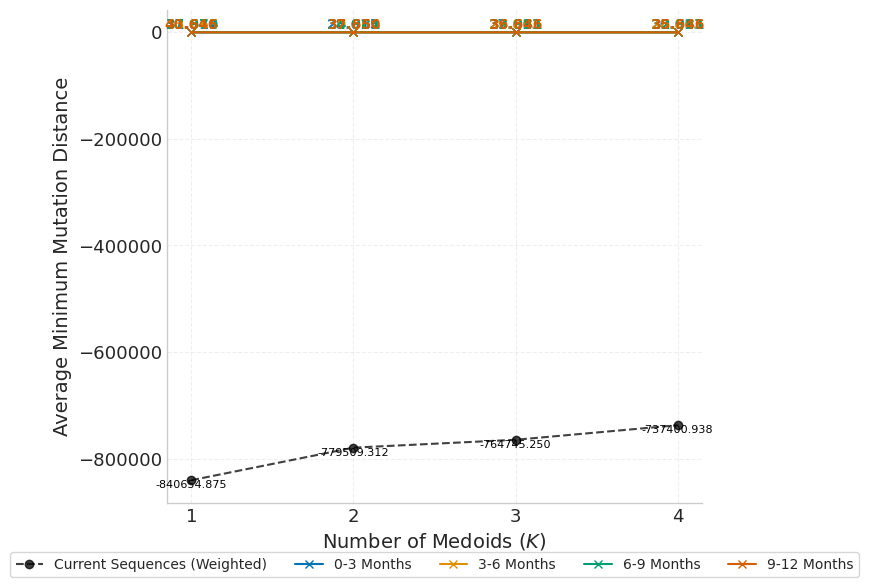

In [43]:
plot_medoid_performance(
    pam_results=pam_results,
    medoid_evaluation_results=medoid_evaluation_results,
    cutoff_date=cutoff_date
)

Score Comparisons

In [42]:
def generate_evaluation_dataframe(pam_results, medoid_evaluation_results, vaccine_results):
    """
    Constructs a DataFrame comparing specific vaccines and K-medoid sets
    across temporal intervals.
    """
    rows = []
    
    # Mapping for consistent column naming
    slice_labels = {
        "3M_1": "0-3 Months",
        "3M_2": "3-6 Months",
        "3M_3": "6-9 Months",
        "3M_4": "9-12 Months"
    }

    # 1. Process Individual Vaccines (e.g., BA.4, BA.5)
    for vaccine_id, intervals in vaccine_results.items():
        row = {"Entity": f"Vaccine: {vaccine_id}"}
        # Map internal interval keys to readable column names
        for k, v in intervals.items():
            row[slice_labels.get(k, k)] = v
        rows.append(row)

    # 2. Process K-Medoid Sets
    # Using k_values from medoid_evaluation_results to ensure alignment
    for k in sorted(medoid_evaluation_results.keys()):
        # Retrieve the specific IDs for this K
        medoid_ids = pam_results[k].get('medoids', [])
        medoid_str = ", ".join(map(str, medoid_ids))
        
        row = {"Entity": f"K={k} Medoids ({medoid_str})"}
        
        # Get evaluation distances for this K
        intervals = medoid_evaluation_results[k]
        for k_int, v_int in intervals.items():
            row[slice_labels.get(k_int, k_int)] = v_int
        rows.append(row)

    # Create DataFrame and set Entity as index (Y-axis)
    df = pd.DataFrame(rows)
    if not df.empty:
        df.set_index("Entity", inplace=True)
        
    return df

evaluation_df = generate_evaluation_dataframe(pam_results, medoid_evaluation_results, vaccine_evaluation_results)

# Display formatted table
print(evaluation_df.to_string())

                                     0-3 Months  3-6 Months  6-9 Months  9-12 Months
Entity                                                                              
Vaccine: BA.4                          0.942116    3.594398   10.027343    14.577087
Vaccine: BA.5                          0.942116    3.594398   10.027343    14.577087
K=1 Medoids (S_169)                   31.613971   33.864812   37.978621    40.646000
K=2 Medoids (S_169, S_47)             28.615164   30.863541   34.980929    37.650464
K=3 Medoids (S_169, S_47, S_3)        27.612684   29.862544   33.980601    36.645739
K=4 Medoids (S_169, S_47, S_3, S_0)   26.613175   28.863089   32.981010    35.646313


Mutation Distance Comparisons

In [33]:
def calculate_and_print_vaccine_medoid_distances(recommended_strains, clade_to_seq, pam_results, id_to_seq):
    """
    Calculates Hamming distance between each vaccine and each individual medoid within each K set.
    Prints results in a hierarchical structured format.
    """
    
    # Helper for single-pair Hamming distance
    def get_hamming(s1, s2):
        if len(s1) != len(s2):
            return None
        return sum(c1 != c2 for c1, c2 in zip(s1, s2))

    print(f"{'='*60}")
    print(f"{'VACCINE VS MEDOID HAMMING DISTANCES':^60}")
    print(f"{'='*60}\n")

    for k in sorted(pam_results.keys()):
        medoid_ids = pam_results[k].get('medoids', [])
        print(f"Configuration: K = {k}")
        print(f"{'-'*30}")

        for m_id in medoid_ids:
            # Retrieve medoid sequence
            m_seq = id_to_seq.get(m_id)
            if m_seq is None:
                print(f"  [!] Medoid {m_id} not found in id_to_seq.")
                continue

            print(f"  Medoid ID: {m_id}")
            
            for vaccine_id in recommended_strains:
                # Retrieve vaccine sequence
                v_seq = clade_to_seq.get(vaccine_id)
                if v_seq is None:
                    print(f"    - vs {vaccine_id:.<15} [!] Not found in clade_to_seq")
                    continue
                
                dist = get_hamming(v_seq, m_seq)
                
                if dist is None:
                    print(f"    - vs {vaccine_id:.<15} Error: Length Mismatch")
                else:
                    print(f"    - vs {vaccine_id:.<15} Distance: {dist}")
            print() # Spacer between medoids
        print(f"{'='*60}\n")

# Usage Call:
calculate_and_print_vaccine_medoid_distances(
    recommended_strains= recommended_strains,
    clade_to_seq=clade_to_seq,
    pam_results=pam_results,
    id_to_seq=id_to_seq
)

            VACCINE VS MEDOID HAMMING DISTANCES             

Configuration: K = 1
------------------------------
  Medoid ID: S_272180
    - vs B.............. Distance: 31
    - vs BA.4........... Distance: 7
    - vs BA.5........... Distance: 7


Configuration: K = 2
------------------------------
  Medoid ID: S_272180
    - vs B.............. Distance: 31
    - vs BA.4........... Distance: 7
    - vs BA.5........... Distance: 7

  Medoid ID: S_536
    - vs B.............. Distance: 27
    - vs BA.4........... Distance: 0
    - vs BA.5........... Distance: 0


Configuration: K = 3
------------------------------
  Medoid ID: S_272180
    - vs B.............. Distance: 31
    - vs BA.4........... Distance: 7
    - vs BA.5........... Distance: 7

  Medoid ID: S_536
    - vs B.............. Distance: 27
    - vs BA.4........... Distance: 0
    - vs BA.5........... Distance: 0

  Medoid ID: S_2601
    - vs B.............. Distance: 28
    - vs BA.4........... Distance: 4
    - vs BA.5...

PyR0 Fitness Score Comparisons

In [34]:
mutation_score_dict_pyro = (
    pyro_df.set_index("mutation")["R / R_A"].to_dict()
)

print(f"Loaded {len(mutation_score_dict_pyro)} PyR₀ mutation scores")

Loaded 2478 PyR₀ mutation scores


In [36]:
# --- Add mutation information to current sequences ---
current_seq_df = add_mutations_column(current_seq_df, id_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
current_seq_df = add_fitness_scores_pyro(current_seq_df, mutation_score_dict_pyro)

In [37]:
# --- Add mutation information to current sequences ---
vaccine_df = add_mutations_column(vaccine_df, clade_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
vaccine_df = add_fitness_scores_pyro(vaccine_df, mutation_score_dict_pyro)

In [44]:
def print_fitness_scores(pam_results, recommended_strains, current_seq_df, vaccine_df):
    """
    Look up and print fitness_score_pyro for medoids and vaccines.
    Uses Sequence_ID as the key for lookup.
    """
    
    # Pre-index DataFrames for O(1) lookup performance
    # Handling cases where IDs might be missing
    fitness_map_medoids = current_seq_df.set_index('Sequence_ID')['Fitness_Score_pyro'].to_dict()
    fitness_map_vaccines = vaccine_df.set_index('Sequence_ID')['Fitness_Score_pyro'].to_dict()

    print(f"{'='*60}")
    print(f"{'FITNESS SCORE (PYRO) EVALUATION':^60}")
    print(f"{'='*60}\n")

    # 1. Print Vaccine Fitness Scores
    print("VACCINE STRAIN SCORES")
    print(f"{'-'*30}")
    for strain in recommended_strains:
        score = fitness_map_vaccines.get(strain, "N/A (Not Found)")
        score_val = f"{score:.5f}" if isinstance(score, float) else score
        print(f"  {strain:.<20} Score: {score_val}")
    print()

    # 2. Print Medoid Fitness Scores per K
    for k in sorted(pam_results.keys()):
        medoid_ids = pam_results[k].get('medoids', [])
        print(f"MEDOIDS FOR K = {k}")
        print(f"{'-'*30}")
        
        for m_id in medoid_ids:
            score = fitness_map_medoids.get(m_id, "N/A (Not Found)")
            score_val = f"{score:.5f}" if isinstance(score, float) else score
            print(f"  ID: {m_id:.<18} Score: {score_val}")
        print()

    print(f"{'='*60}")

print_fitness_scores(pam_results, recommended_strains, current_seq_df, vaccine_df)

              FITNESS SCORE (PYRO) EVALUATION               

VACCINE STRAIN SCORES
------------------------------
  BA.4................ Score: 4.42300
  BA.5................ Score: 4.42300

MEDOIDS FOR K = 1
------------------------------
  ID: S_169............. Score: 1.41177

MEDOIDS FOR K = 2
------------------------------
  ID: S_169............. Score: 1.41177
  ID: S_47.............. Score: 1.17439

MEDOIDS FOR K = 3
------------------------------
  ID: S_169............. Score: 1.41177
  ID: S_47.............. Score: 1.17439
  ID: S_3............... Score: 1.00000

MEDOIDS FOR K = 4
------------------------------
  ID: S_169............. Score: 1.41177
  ID: S_47.............. Score: 1.17439
  ID: S_3............... Score: 1.00000
  ID: S_0............... Score: 1.18443

